In [2]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [3]:
Henber_point_path = 'G:\ICESat-2\FB_importance\Henber_2019_sample_points_final.shp'
Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
Ribble_point_path = 'G:\ICESat-2\FB_importance\Ribble1_2021_sample_points_final.shp'
Solway_point_path = 'G:\ICESat-2\FB_importance\Solway_2023_sample_points_final.shp'
Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'

In [7]:
k = gpd.read_file(Wash_point_path)
k.shape[0]
a =0
for path in [Henber_point_path, Morecambe_point_path, Ribble_point_path, Solway_point_path, Thames_point_path, Wash_point_path]:
    
    k = gpd.read_file(path)
    a += k.shape[0]

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 示例数据
x = np.array(k['Refer_dem'])
y = np.array(k['b9_T'])

# 计算 Pearson 相关系数和 p 值
corr, p_value = pearsonr(x, y)

# 绘制散点图
plt.figure(figsize=(5, 5))
plt.scatter(x, y, color='dodgerblue', edgecolor='black', s=10)
plt.title(f"Scatter Plot\nPearson Correlation = {corr:.2f}", fontsize=14)
plt.xlabel("X")
plt.ylabel("Y")

# 可选：添加趋势线（线性拟合）
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color='red', linestyle='--', label='Linear Fit')
plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()


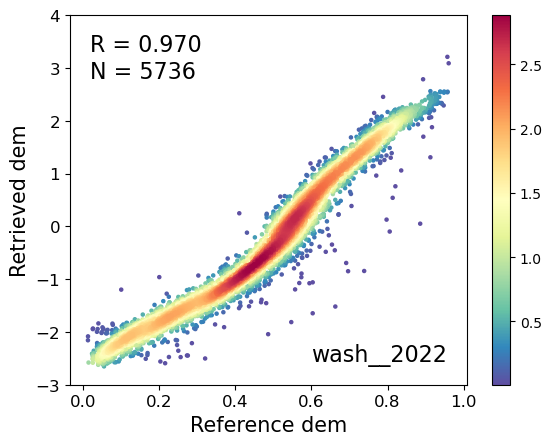

In [85]:

k = gpd.read_file(Wash_point_path)
k = k[k['DTM_B1']!=0]
x = np.array(k['Refer_dem'])
y = np.array(k['Freq'])
# y = np.array(k['DTM_B5'])
R, _ = pearsonr(y, x)
R2 = r2_score(x, y)
MAD = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R2 = {R:.3f}\nMAE = {MAD:.3f}\nRMSE = {RMSE:.3f} \nN = {num}"
textstr = f"R = {R:.3f} \nN = {num}"
# name = f'{'Wash'} ({year})'
name = f'wash__2022'
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 15)
ax.set_ylabel('Retrieved dem', fontsize = 15)
# ax.plot([0, 0.1], [-3, 4], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

# plt.scatter(x, y,c=z, s=2,cm[-3, 4], ap='Spectral_r') # c表示标记的颜色
# plt.colorbar()

# ax.set_xlim(-3, 4)
ax.set_ylim(-3, 4)
ax.tick_params(axis='both', labelsize=12)
# output_path = f"G:\ICESat-2\Discussion5_2\graph/wash_{obs_num}_Freq_2022.png"  # 例如："./output/plot.png"
# plt.savefig(output_path, dpi=300, bbox_inches='tight') 
plt.show()

In [49]:
k = gpd.read_file(Wash_point_path)
k.columns

Index(['Refer_dem', 'retrieved_', 'AAA', 'SY', 'b1_T', 'b2_T', 'b3_T', 'b4_T',
       'b5_T', 'b6_T', 'b7_T', 'b8_T', 'b9_T', 'b10_T', 'b11_T', 'DTM_B1',
       'DTM_B2', 'DTM_B3', 'DTM_B4', 'DTM_B5', 'DTM_B6', 'DTM_B7', 'DTM_B8',
       'mean_MNDWI', 'mean_B1', 'mean_RE1', 'mean_RE2', 'mean_RE3', 'Freq',
       'mean_B1_1', 'mean_Blue', 'mean_Green', 'mean_MND_1', 'mean_NDWI',
       'mean_NIR', 'mean_RE1_1', 'mean_RE2_1', 'mean_RE3_1', 'mean_RE4',
       'mean_Red', 'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min',
       'geometry'],
      dtype='object')

In [13]:
k = gpd.read_file(Morecambe_point_path)
k1 = k[band_list]
b = gpd.read_file(Ribble_point_path)
b1 = k[band_list]
print(k1.shape)
c = pd.concat([k1, b1], axis=0)
c.shape

(9271, 24)


(18542, 24)

In [4]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# 假设有 100 个样本，每个样本有 6 个波段特征
Henber_point_path = 'G:\ICESat-2\FB_importance\Henber_2019_sample_points_final.shp'
Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
Ribble_point_path = 'G:\ICESat-2\FB_importance\Ribble1_2021_sample_points_final.shp'
Solway_point_path = 'G:\ICESat-2\FB_importance\Solway_2023_sample_points_final.shp'
Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Solway_point_path, Thames_point_path, Wash_point_path]

k = gpd.read_file(Morecambe_point_path)
print(k.shape)
band_list = ['Freq','mean_B1' ,'mean_Blue', 'mean_Green', 'mean_MNDWI', 'mean_NDWI','mean_NIR', 'mean_RE1', 'mean_RE2', 'mean_RE3',
             'mean_RE4','mean_Red', 'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min','Refer_dem',
             'mean_SR_B1', 'mean_SR_B2', 'mean_SR_B3', 'mean_SR_B4','mean_SR_B5', 'mean_SR_B6', 'mean_SR_B7']
empty = []
for i in range(6):
    k = gpd.read_file(list[i])
    k_fb = k[band_list]
    empty.append(k_fb)

collect = pd.concat(empty, axis=0)

band_list1 = ['Freq','mean_B1' ,'mean_Blue', 'mean_Green', 'mean_MNDWI', 'mean_NDWI','mean_NIR', 'mean_RE1', 'mean_RE2', 'mean_RE3',
             'mean_RE4','mean_Red', 'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min']

band_list2 = ['Freq', 'mean_MNDWI', 'mean_RE4', 'mean_NIR','mean_RE3','mean_RE2',
              'mean_MNDWI','mean_SR_B5','mean_SWIR1', 'mean_SWIR2','mean_SR_B6',
              'mean_RE1','min_MNDWI', 'mean_SR_B7', 'mean_SR_B4', 'mean_Red',
              'mean_SR_B1', 'mean_SR_B2', 'mean_SR_B3', 'mean_B1', 'mean_Green',
              'mean_Blue', 'NDWI_min']

df = k[band_list]#,'b2_T','b3_T','b4_T','b5_T','b6_T'
df = collect[band_list]
y = k['Refer_dem']

corrs = df.corr()['Refer_dem'].drop('Refer_dem')
selected = corrs.abs().sort_values(ascending=False)
print(selected)
# # 构建并训练模型
# clf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=30)
# clf.fit(X, y)

# # 查看各特征重要性
# importances = clf.feature_importances_
# print(importances)
# # 可视化
# plt.figure(figsize=(8,4))
# plt.bar(X.columns, importances, color='skyblue', edgecolor='black')
# plt.title("Feature Importances")
# plt.ylabel("Importance")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()


(9271, 47)
Freq          0.867664
mean_NDWI     0.840203
mean_RE4      0.827310
mean_NIR      0.821778
mean_RE3      0.812623
mean_RE2      0.805116
mean_MNDWI    0.794422
mean_SR_B5    0.778831
mean_SWIR1    0.770678
mean_SWIR2    0.739330
mean_SR_B6    0.726931
mean_RE1      0.711804
min_MNDWI     0.696297
mean_SR_B7    0.693020
mean_SR_B4    0.654563
mean_Red      0.607087
mean_SR_B1    0.565497
mean_SR_B2    0.551550
mean_SR_B3    0.503783
mean_B1       0.344985
mean_Green    0.333561
mean_Blue     0.322189
NDWI_min      0.229082
Name: Refer_dem, dtype: float64


In [5]:
Henber_point_path = 'G:\ICESat-2\FB_importance\Henber_2019_sample_points_final.shp'
Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
Ribble_point_path = 'G:\ICESat-2\FB_importance\Ribble1_2021_sample_points_final.shp'
Solway_point_path = 'G:\ICESat-2\FB_importance\Solway_2023_sample_points_final.shp'
Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'

list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Solway_point_path, Thames_point_path, Wash_point_path]
null = []
for i in range(len(list)):
    
    path = list[i]
    k = gpd.read_file(path)

    # df = k[['b1_T','b2_T','b3_T','b4_T','b5_T','b6_T','b7_T','b8_T','b9_T','Refer_dem']]
    df = k[band_list]

    corrs = df.corr()['Refer_dem'].drop('Refer_dem')

    # 用绝对值排序
    selected = corrs.abs().sort_values(ascending=False)
    # print(selected)
    null.append(selected)

In [6]:
l = np.array(null)

std = np.std(l, axis=0)
print(std)
mean = np.mean(l, axis=0)
print(mean)

[0.02667114 0.03668262 0.03959497 0.02959787 0.03393479 0.04035286
 0.03817249 0.07149418 0.06836845 0.06694477 0.067905   0.06550093
 0.07567689 0.07811947 0.07813716 0.07849271 0.10045269 0.09312719
 0.12950939 0.12111572 0.1426798  0.17132265 0.15739856]
[0.93986366 0.91639208 0.8808994  0.86117838 0.8517601  0.84139741
 0.83214262 0.79627069 0.76381623 0.74637055 0.72771021 0.71591629
 0.69450739 0.67454228 0.64175125 0.62765923 0.59128742 0.55704746
 0.51070408 0.43058283 0.37360988 0.32540795 0.2563655 ]


Text(0, 0.5, 'Absolute Pearson R')

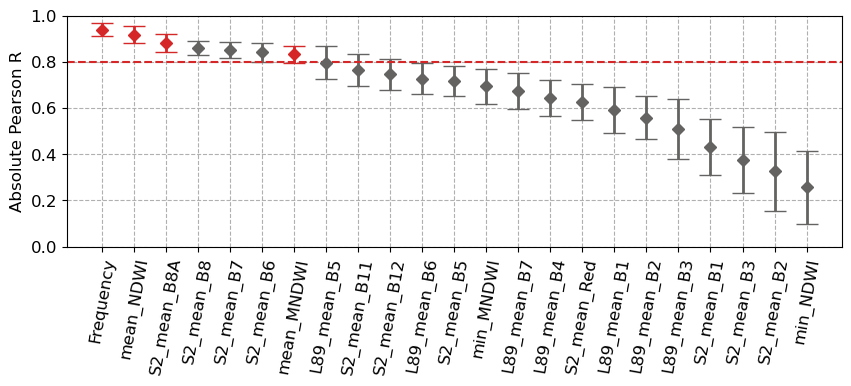

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))

# x = np.array(['Frequency','mean_B1' ,'mean_Blue', 'mean_Green', 'mean_MNDWI', 'mean_NDWI','mean_NIR', 
#               'mean_RE1', 'mean_RE2', 'mean_RE3', 'mean_RE4','mean_Red', 
#               'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min',
#               'mean_SR_B1', 'mean_SR_B2', 'mean_SR_B3', 'mean_SR_B4','mean_SR_B5', 'mean_SR_B6', 'mean_SR_B7'])
x = np.array(['Freq', 'mean_NDWI', 'mean_RE4', 'mean_NIR','mean_RE3','mean_RE2',
              'mean_MNDWI','mean_SR_B5','mean_SWIR1', 'mean_SWIR2','mean_SR_B6',
              'mean_RE1','min_MNDWI', 'mean_SR_B7', 'mean_SR_B4', 'mean_Red',
              'mean_SR_B1', 'mean_SR_B2', 'mean_SR_B3', 'mean_B1', 'mean_Green',
              'mean_Blue', 'NDWI_min'])

x = np.array(['Frequency', 'mean_NDWI', 'S2_mean_B8A', 'S2_mean_B8','S2_mean_B7','S2_mean_B6',
              'mean_MNDWI','L89_mean_B5','S2_mean_B11', 'S2_mean_B12','L89_mean_B6',
              'S2_mean_B5','min_MNDWI', 'L89_mean_B7', 'L89_mean_B4', 'S2_mean_Red',
              'L89_mean_B1', 'L89_mean_B2', 'L89_mean_B3', 'S2_mean_B1', 'S2_mean_B3',
              'S2_mean_B2', 'min_NDWI'])

for i in range(len(x)):
    color = "#D62728" if (i==0)|(i==1)|(i==2)|(i==6)  else "#656262" #"#F39E61"
    ax.errorbar(x[i], mean[i], yerr=std[i], fmt='D', color=color, ecolor=color,
                capsize=8, elinewidth=2, linewidth=4)

# 添加 0.8 的参考线
ax.axhline(y=0.8, color='#D62728', linestyle='--', linewidth=1.5)

ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.set_ylim(0, 1)
ax.tick_params(axis='both', labelsize=12)
plt.xticks(rotation=80)
ax.set_ylabel('Absolute Pearson R', fontsize=12)


In [8]:
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
k = gpd.read_file(Thames_point_path)
k = k[k['DTM_B1']!=0]
null = []
for i in range(8):
    
    
    x = np.array(k['Refer_dem'])
    y = np.array(k[f'DTM_B{i+1}'])
    R, _ = pearsonr(y, x)
    R2 = r2_score(x, y)
    # MAD = np.mean(np.abs(y-x))
    # MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    print('R2:', R2, ' RMSE:', RMSE)
    # num = int(len(x))


R2: 0.4625914937922103  RMSE: 0.5892453981221452
R2: 0.4453594608830145  RMSE: 0.5986179509170034
R2: 0.42229514391630274  RMSE: 0.6109377208669688
R2: 0.42895577905372706  RMSE: 0.6074056141634241
R2: 0.42615232833938177  RMSE: 0.608894769302093
R2: 0.4401799155370185  RMSE: 0.6014065711973412
R2: 0.39682370929364597  RMSE: 0.6242607969246761
R2: 0.40228232387562346  RMSE: 0.6214296646893204


In [ ]:
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
band_list2 = ["NAEF","mean_NDWI", "mean_MNDWI","mean_RE4","mean_NIR", "mean_RE2", "mean_RE3",'mean_SR_B5']
df = gpd.read_file(Morecambe_point_path)
df_ = df[band_list2].values
df_v = df_#.reshape(16, -1)
df_v.shape
# X_sim = np.random.randn(n_samples, len(bands))


(9271, 8)

Text(0, 0.5, 'Absolute Pearson coefficient (R)')

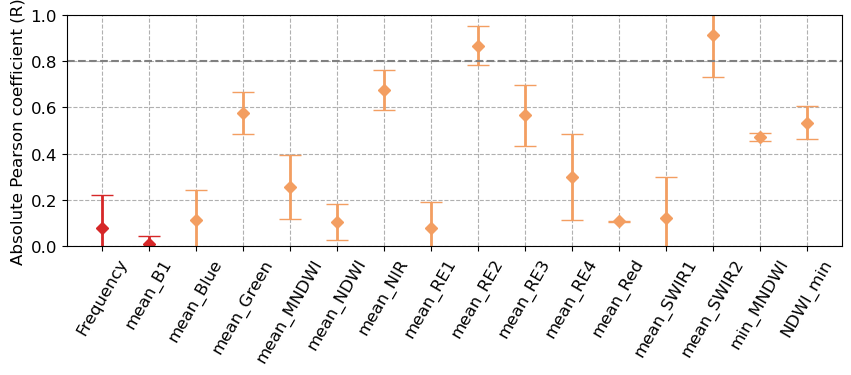

(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5]),
 [Text(0, 0.5, 'Freq'),
  Text(0, 1.5, 'mean_NDWI'),
  Text(0, 2.5, 'mean_MNDWI'),
  Text(0, 3.5, 'mean_RE4'),
  Text(0, 4.5, 'mean_NIR'),
  Text(0, 5.5, 'mean_RE2'),
  Text(0, 6.5, 'mean_RE3'),
  Text(0, 7.5, 'mean_SR_B5')])

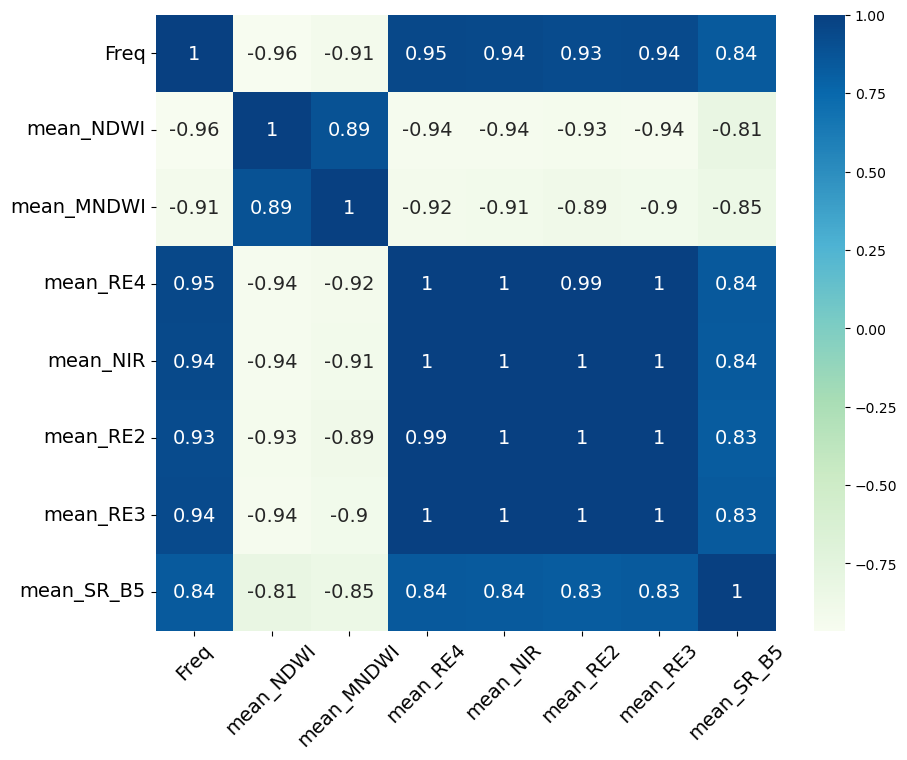

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = pd.DataFrame(df_v).corr()
plt.figure(figsize=(10, 8))
# sns.heatmap(corr, annot=True, cmap='coolwarm')
sns.heatmap(corr, annot=True, cmap='GnBu',
            xticklabels=band_list2,
            yticklabels=band_list2, annot_kws={"size": 14})
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xticks(rotation=45)  # 如果名字太长可以旋转
plt.yticks(rotation=0)
# plt.xlabel("Features", fontsize=14)
# plt.ylabel("Features", fontsize=14)


--- VIF 结果 ---
       Feature           VIF
8     mean_RE2  34154.947176
9     mean_RE3  32880.660083
3   mean_Green  17798.117539
7     mean_RE1  13422.897384
10    mean_RE4   8603.991534
6     mean_NIR   7717.995475
2    mean_Blue   5731.010292
11    mean_Red   5549.492603
12  mean_SWIR1   1710.141122
13  mean_SWIR2    905.450925
1      mean_B1    545.641130
4   mean_MNDWI    355.902193
5    mean_NDWI    234.988303
0         Freq    126.919629
15    NDWI_min     40.563876
14   min_MNDWI     12.044646


C:\Users\minyu\AppData\Local\Temp\ipykernel_36160\2717073557.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="VIF", y="Feature", data=vif_result, palette="Blues_d")


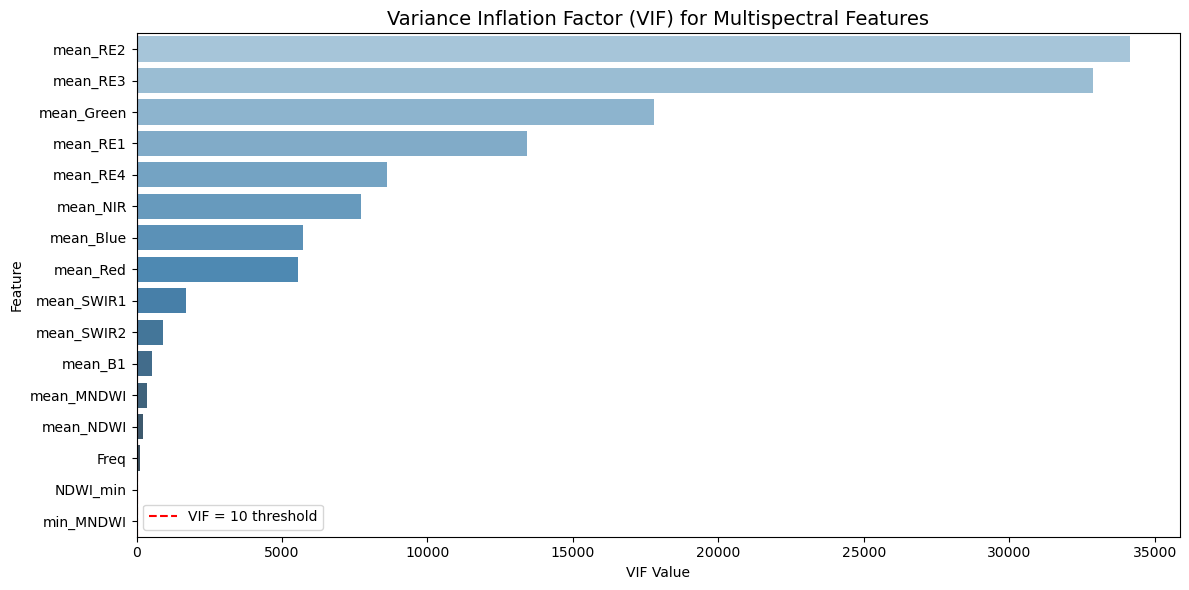

In [138]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
band_list2 = ["Freq", "mean_RE4", "mean_MNDWI","mean_NDWI","mean_NIR", "mean_RE1", "mean_RE2", "mean_RE3"]
band_list2 = ["Freq","mean_NDWI","mean_RE4"]
# 示例：假设你已经有一个多光谱特征DataFrame（X），列为波段，行为样本
# 假设列名如下（请根据实际数据替换）
band_list2 = [
    "Freq", "mean_B1", "mean_Blue", "mean_Green", "mean_MNDWI",
    "mean_NDWI", "mean_NIR", "mean_RE1", "mean_RE2", "mean_RE3",
    "mean_RE4", "mean_Red", "mean_SWIR1", "mean_SWIR2",
    "min_MNDWI", "NDWI_min"
]

# 示例数据：200个样本，模拟有线性相关性
np.random.seed(42)
n_samples = 200
X_sim = df[band_list2]


# 构建 DataFrame
X_df = pd.DataFrame(X_sim, columns=band_list2)

# 计算 VIF
def calculate_vif(df):
    vif_df = pd.DataFrame()
    vif_df["Feature"] = df.columns
    vif_df["VIF"] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
    return vif_df.sort_values(by="VIF", ascending=False)

vif_result = calculate_vif(X_df)

# 显示 VIF 表格
print("\n--- VIF 结果 ---")
print(vif_result)

# 绘制 VIF 条形图
plt.figure(figsize=(12, 6))
sns.barplot(x="VIF", y="Feature", data=vif_result, palette="Blues_d")
plt.axvline(x=10, color='r', linestyle='--', label='VIF = 10 threshold')
plt.title("Variance Inflation Factor (VIF) for Multispectral Features", fontsize=14)
plt.xlabel("VIF Value")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
plt.show()


In [27]:
path = 'G:\FB_new7\Morecambe_new7\Morecambe_points2_.shp'
points = gpd.read_file(path)
points.columns

Index(['Id', 'ORIG_FID', 'Id_1', 'mean_NDWI', 'Freq', 'geometry'], dtype='object')

C:\Users\minyu\AppData\Local\Temp\ipykernel_9164\362626567.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))


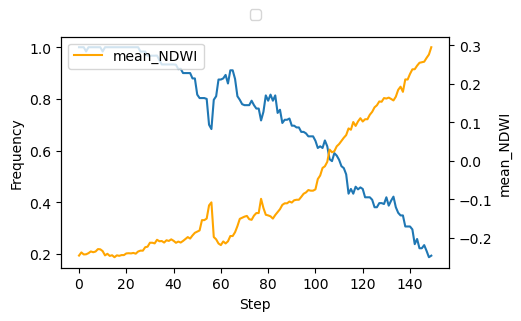

In [ ]:
fig, ax1 = plt.subplots(figsize=(5,3))
ax1.plot(points['Freq'])
ax1.set_ylabel('Frequency')
ax2 = ax1.twinx()
ax2.plot(points['mean_NDWI'], color = 'orange', label = 'mean_NDWI')
ax2.set_ylabel('mean_NDWI')
ax1.set_xlabel('Step')
ax2.legend()
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))
# ax2.plot(points['mean_B8A'], color = 'orange')


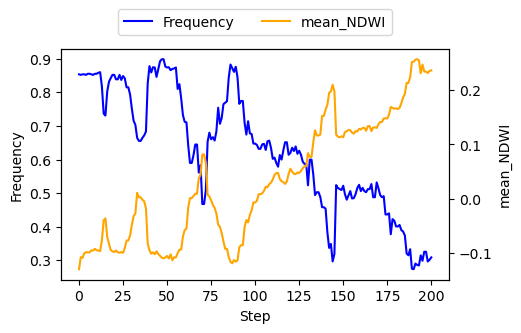

In [28]:
fig, ax1 = plt.subplots(figsize=(5, 3))

# 画第一条线（Freq）
line1, = ax1.plot(points['Freq'], label='Frequency', color='blue')
ax1.set_ylabel('Frequency')

# 第二坐标轴（NDWI）
ax2 = ax1.twinx()
line2, = ax2.plot(points['mean_NDWI'], label='mean_NDWI', color='orange')
ax2.set_ylabel('mean_NDWI')

# X轴标签
ax1.set_xlabel('Step')

# 合并图例
lines = [line1, line2]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, 1.2), ncol=2)
